# LK06 - EDA snapshot `dataset-v3.0.0`

EDA untuk menentukan rancangan klasifikasi Random Forest, sebelum tuning dan integrasi MLflow. Sumber: dua CSV yang dilacak DVC, **bukan** cache `data/processed/`.

Target adalah **pseudo-label deterministik** dari `AnomalyLabeler`: 0 normal, 1 hardware fault, 2 cuaca ekstrem. Tidak ada anotasi sensor lapangan independen. EDA dapat mendukung pemilihan kandidat model; EDA tidak membuktikan algoritma yang paling unggul.

Seluruh snapshot diperiksa secara deskriptif untuk audit kualitas, cakupan kelas, dan kelayakan split. Ini bukan blind holdout sepenuhnya: distribusi label test sudah diinspeksi. Tidak ada model yang dilatih atau dipilih dalam notebook ini. Pada tahap berikutnya, pemilihan hyperparameter harus memakai validation; test hanya untuk evaluasi final. Validasi eksternal yang lebih kuat membutuhkan snapshot baru.

In [ ]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import logging
import subprocess
import sys
import warnings

warnings.filterwarnings('ignore', message='.*Pyarrow.*', category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / '1_data_preprocessing.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / '1_data_preprocessing.py').exists(), 'Jalankan dari root repo atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data_preprocessing import WeatherPreprocessor, RAW_COLUMNS
from src.simulate_data import FaultInjector

OUT = ROOT / 'Documentation' / 'LK06' / 'eda'
OUT.mkdir(parents=True, exist_ok=True)
PATHS = {
    'raw': ROOT / 'data/raw/weather_raw_current.csv',
    'faults': ROOT / 'data/simulated/weather_faults_s42.csv',
}
EXPECTED = {
    'raw': '9684e1329ae170b08883d1ea643eb174',
    'faults': '64d906e7d0086d1814f5e61b359e22fe',
}
LABELS = ['0 Normal', '1 Hardware fault', '2 Extreme weather']
COLORS = ['#367e72', '#cf554d', '#d89c32']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def git(*args):
    return subprocess.check_output(['git', *args], cwd=ROOT, text=True).strip()

def savefig(name):
    plt.savefig(OUT / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

raw = {name: pd.read_csv(path) for name, path in PATHS.items()}
processed = {name: WeatherPreprocessor().process(frame) for name, frame in raw.items()}
provenance = {
    'git_commit': git('rev-parse', 'HEAD'),
    'dataset_tag_commit': git('rev-parse', 'dataset-v3.0.0^{commit}'),
    'preprocessing_code_sha256': hashlib.sha256((ROOT/'src/1_data_preprocessing.py').read_bytes()).hexdigest(),
    'versions': {p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'matplotlib']},
    'dataset_md5': {k: hashlib.md5(p.read_bytes()).hexdigest() for k,p in PATHS.items()},
}
assert provenance['dataset_md5'] == EXPECTED, 'Dataset berbeda dari snapshot audit v3; perbarui EDA secara eksplisit.'
for name, path in PATHS.items():
    pointer = git('show', f'dataset-v3.0.0:{path.relative_to(ROOT).as_posix()}.dvc')
    assert EXPECTED[name] in pointer
print(json.dumps(provenance, indent=2))

## 1. Skema, kualitas, dan kontinuitas waktu

Snapshot berisi 720 jam pada 20 September-19 Oktober 2026. Timestamp CSV bersifat naive; kontrak ingestion menggunakan `Asia/Jakarta`. Sumber ingestion adalah endpoint **forecast**, dengan `forecast_days=1`: nilai API bukan pengukuran sensor fisik, dan ujung snapshot dapat memuat jam prakiraan/revisi. Hindari menyebut evaluasi ini sebagai uji sensor nyata atau historical backtest yang merekonstruksi informasi saat itu.

In [2]:
quality_rows = []
for name, frame in raw.items():
    df = processed[name]
    x = df.drop(columns=['timestamp', 'anomaly_class', 'anomaly_reason'])
    quality_rows.append({
        'dataset': name, 'rows': len(frame), 'raw_columns': len(frame.columns),
        'processed_columns': len(df.columns), 'candidate_features': len(x.columns),
        'start': str(df.timestamp.min()), 'end': str(df.timestamp.max()),
        'invalid_timestamps': int(pd.to_datetime(frame.timestamp, errors='coerce').isna().sum()),
        'duplicate_timestamps': int(frame.timestamp.duplicated().sum()),
        'missing_raw_cells': int(frame.isna().sum().sum()),
        'non_hourly_steps': int(df.timestamp.diff().dropna().ne(pd.Timedelta(hours=1)).sum()),
        'nonfinite_feature_cells': int((~np.isfinite(x.to_numpy())).sum()),
    })
quality = pd.DataFrame(quality_rows).set_index('dataset')
display(quality)
quality.to_csv(OUT / 'quality.csv')
display(raw['raw'].select_dtypes('number').describe().T.round(3))
raw['raw'].select_dtypes('number').describe().T.to_csv(OUT / 'raw_descriptive_statistics.csv')
assert all(quality.rows == 720)
assert all(quality[['invalid_timestamps','duplicate_timestamps','missing_raw_cells','non_hourly_steps','nonfinite_feature_cells']].eq(0).all())

,rows,raw_columns,processed_columns,candidate_features,start,end,invalid_timestamps,duplicate_timestamps,missing_raw_cells,non_hourly_steps,nonfinite_feature_cells
dataset,,,,,,,,,,,
raw,720,7,40,37,2026-09-20 00:00:00,2026-10-19 23:00:00,0,0,0,0,0
faults,720,7,40,37,2026-09-20 00:00:00,2026-10-19 23:00:00,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
temperature_2m_C,720.0,24.332,3.914,17.600,21.100,23.10,27.80,34.000
humidity_percent,720.0,71.856,21.759,21.000,53.000,78.00,91.00,100.000
precipitation_mm,720.0,0.056,0.281,0.000,0.000,0.00,0.00,4.100
soil_moisture,720.0,0.182,0.055,0.102,0.133,0.18,0.22,0.326
radiation_wm2,720.0,292.711,371.845,0.000,0.000,15.00,633.00,1065.000
wind_speed_kmh,720.0,5.446,2.993,0.400,3.100,4.90,7.20,14.200


## 2. Audit cache processed dan reproduksibilitas simulasi

File processed lama harus diverifikasi terhadap input, bukan dipercaya dari namanya. EDA memakai `WeatherPreprocessor.process()` di memori, sehingga tidak menimpa raw, simulated, atau processed yang sudah ada. Hash file DVC tetap dijaga.

In [3]:
cache_rows = []
for path in sorted((ROOT/'data/processed').glob('*.csv')):
    saved = pd.read_csv(path, parse_dates=['timestamp'])
    source = 'faults' if 'faults' in path.name else 'raw'
    try:
        pd.testing.assert_frame_equal(saved, processed[source], check_dtype=False, rtol=1e-9, atol=1e-9)
        matches = True
    except AssertionError:
        matches = False
    cache_rows.append({
        'file': path.name, 'rows': len(saved), 'start': str(saved.timestamp.min()),
        'end': str(saved.timestamp.max()), 'matches_expected_current_source': matches,
        **{f'class_{k}': int(saved.anomaly_class.eq(k).sum()) for k in [0,1,2]},
    })
cache_audit = pd.DataFrame(cache_rows)
display(cache_audit)
cache_audit.to_csv(OUT/'processed_cache_audit.csv', index=False)

replay = FaultInjector(seed=42, fault_rate=0.05).apply(raw['raw'])
np.testing.assert_allclose(replay[RAW_COLUMNS[1:]], raw['faults'][RAW_COLUMNS[1:]], rtol=1e-12, atol=1e-12)
changed = raw['raw'][RAW_COLUMNS[1:]].ne(raw['faults'][RAW_COLUMNS[1:]]).any(axis=1)
print('Baris sensor yang berubah:', int(changed.sum()))
print('Baris tidak diubah yang tetap dilabeli fault:', int((~changed & processed['faults'].anomaly_class.eq(1)).sum()))
print('Replay simulasi seed=42 cocok numerik dengan snapshot DVC.')
transitions = pd.crosstab(processed['raw'].anomaly_class, processed['faults'].anomaly_class).reindex(index=[0,1,2], columns=[0,1,2], fill_value=0)
transitions.index.name='raw_class'; transitions.columns.name='simulated_class'
display(transitions)
transitions.to_csv(OUT/'label_transitions.csv')

,file,rows,start,end,matches_expected_current_source,class_0,class_1,class_2
0,weather_features_faults_s42.csv,720,2026-09-14 00:00:00,2026-10-13 23:00:00,False,610,58,52
1,weather_features_v1.0.csv,720,2026-09-14 00:00:00,2026-10-13 23:00:00,False,610,58,52
2,weather_processed_current.csv,720,2026-09-14 00:00:00,2026-10-13 23:00:00,False,610,58,52


2026-10-19 12:55:33,332 [INFO] simulate_data: Fault sintetis diinjeksikan (seed=42): {'temp_stuck_block': 1, 'soil_oob': 5, 'temp_oob': 7, 'temp_spike': 13, 'humidity_oob': 6, 'negative_value': 4, 'night_radiation': 1}


Baris sensor yang berubah: 53
Baris tidak diubah yang tetap dilabeli fault: 18
Replay simulasi seed=42 cocok numerik dengan snapshot DVC.


simulated_class,0,1,2
raw_class,,,
0,590,51,0
1,0,0,0
2,0,10,69


## 3. Distribusi kelas dan sumber label

Data asli tidak menyediakan Class 1; training multiclass harus memakai dataset simulasi. Jangan menggabungkan raw dan simulated lalu membagi baris secara acak: keduanya berasal dari timestamp dan konteks cuaca yang sama.

`fault_rate=0.05` berarti 36 injeksi titik, ditambah blok stuck 18 jam; bukan jaminan 5% label hardware fault. Aturan temporal dapat menandai baris setelah lonjakan. Dari 53 baris sensor yang benar-benar berubah, hasil akhir memuat 61 label fault; 18 fault ada pada baris yang nilainya tidak diubah. Ini efek labeler, bukan anotasi independen tentang titik injeksi.

,raw,faults
anomaly_class,,
0,641,590
1,0,61
2,79,69


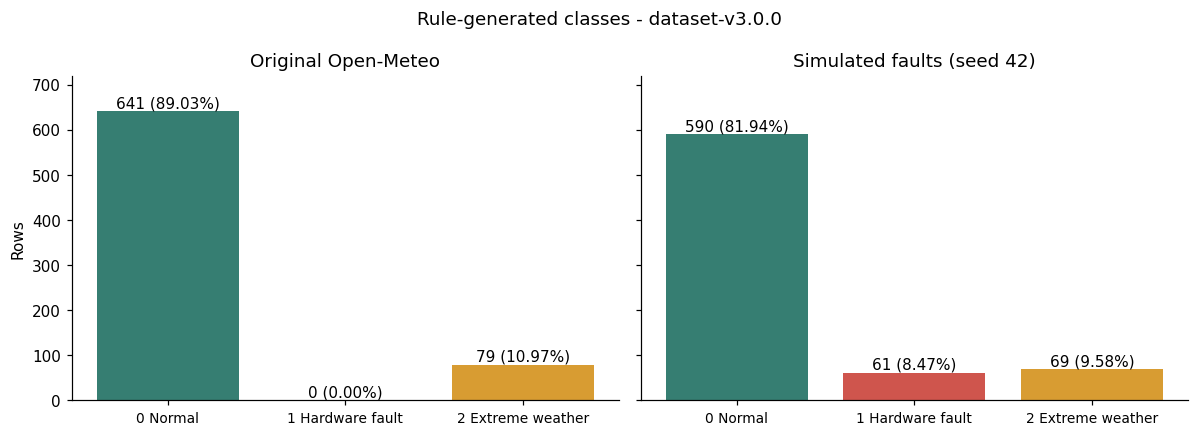

,reason,rows
0,Normal State,590
1,Extreme Weather: Severe Dry Air,68
2,Hardware Fault: Temperature spike,31
3,Hardware Fault: Temperature sensor stuck,7
4,Hardware Fault: Temperature OOB,7
5,Hardware Fault: Humidity OOB,6
6,Hardware Fault: Soil moisture OOB,5
7,Hardware Fault: Negative wind speed,2
8,Hardware Fault: Night radiation glitch,1
9,Hardware Fault: Negative radiation,1


In [4]:
counts = pd.DataFrame({name: df.anomaly_class.value_counts().reindex([0,1,2], fill_value=0) for name,df in processed.items()})
display(counts)
counts.to_csv(OUT/'class_counts.csv')
fig, axes = plt.subplots(1,2, figsize=(11,4), sharey=True)
for ax, name in zip(axes, ['raw','faults']):
    vals = counts[name].to_numpy()
    ax.bar(LABELS, vals, color=COLORS)
    for i, n in enumerate(vals): ax.text(i, n+8, f'{n} ({n/720:.2%})', ha='center')
    ax.set_title('Original Open-Meteo' if name=='raw' else 'Simulated faults (seed 42)')
    ax.tick_params(axis='x', labelsize=9)
    ax.set_ylim(0,720)
axes[0].set_ylabel('Rows')
fig.suptitle('Rule-generated classes - dataset-v3.0.0')
fig.tight_layout()
savefig('01_class_distribution.png')

reasons = processed['faults'].anomaly_reason.str.replace(r'\s*\(.*', '', regex=True)
reason_counts = reasons.value_counts().rename_axis('reason').reset_index(name='rows')
display(reason_counts)
reason_counts.to_csv(OUT/'reason_counts.csv', index=False)

## 4. Profil temporal dan pergeseran distribusi

Plot berikut bersifat deskriptif. Penyebaran anomali tidak merata antar waktu; random split tidak merepresentasikan penggunaan pada waktu berikutnya. Hampir semua label cuaca ekstrem berasal dari kelembaban <40%: 68 severe dry air dan hanya satu heatwave pada dataset simulasi. Dataset ini belum menguji semua tipe cuaca ekstrem yang tertulis di taksonomi.

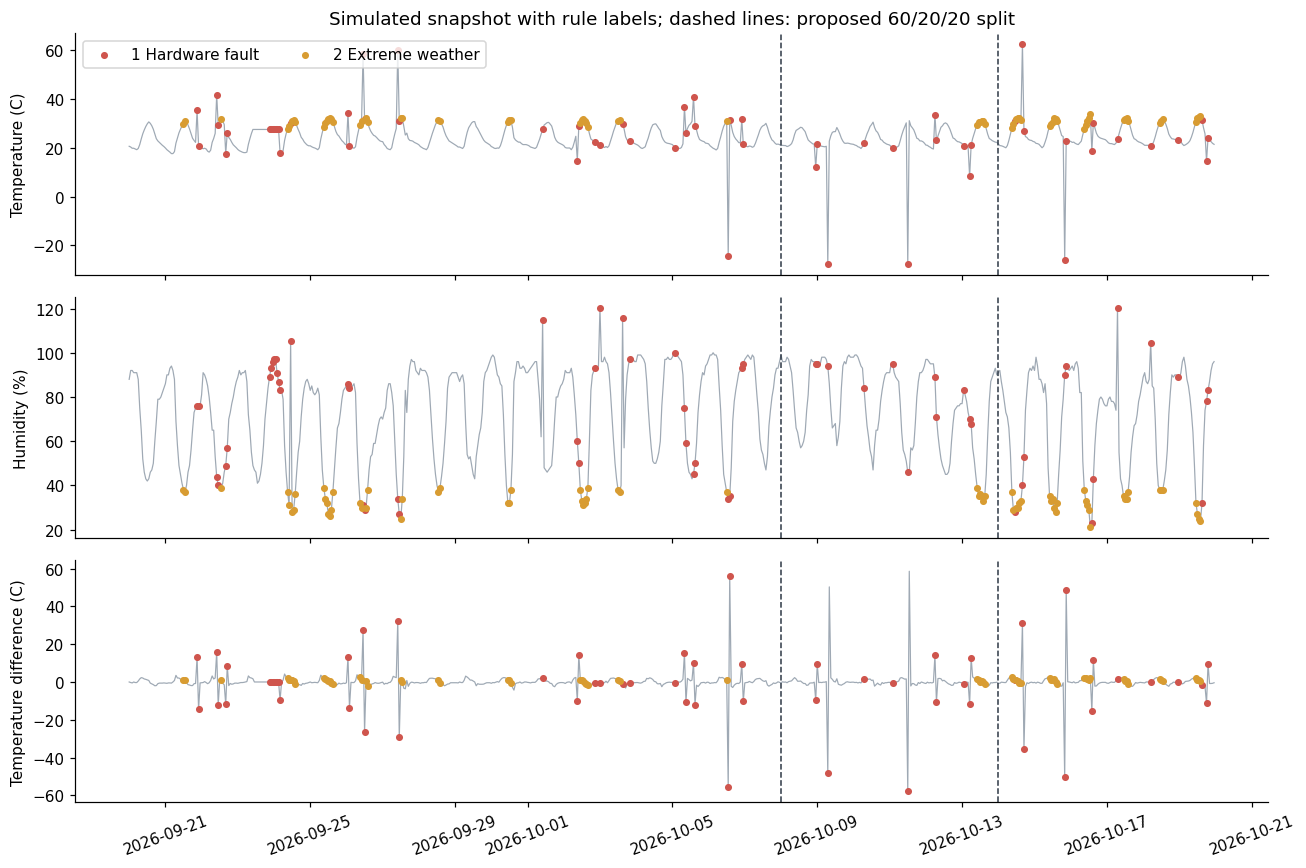

anomaly_class,0,1,2
timestamp,,,
2026-09-14/2026-09-20,24,0,0
2026-09-21/2026-09-27,126,21,21
2026-09-28/2026-10-04,148,7,13
2026-10-05/2026-10-11,152,15,1
2026-10-12/2026-10-18,123,15,30
2026-10-19/2026-10-25,17,3,4


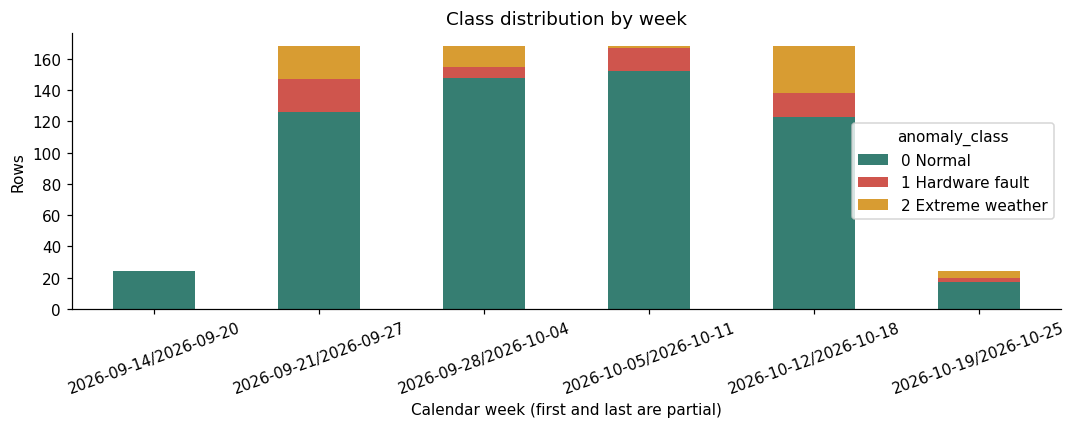

In [5]:
df = processed['faults']
fig, axes = plt.subplots(3,1,figsize=(12,8), sharex=True)
for ax, col, ylabel in zip(axes, ['temperature_2m_C','humidity_percent','temp_diff_1h'], ['Temperature (C)','Humidity (%)','Temperature difference (C)']):
    ax.plot(df.timestamp, df[col], color='#8794a2', linewidth=0.8, alpha=0.8)
    for cls in [1,2]:
        mask=df.anomaly_class.eq(cls)
        ax.scatter(df.loc[mask,'timestamp'], df.loc[mask,col], s=13, color=COLORS[cls], label=LABELS[cls], zorder=3)
    ax.set_ylabel(ylabel)
    ax.axvline(df.timestamp.iloc[432], color='#2d3845', linestyle='--', linewidth=1)
    ax.axvline(df.timestamp.iloc[576], color='#2d3845', linestyle='--', linewidth=1)
axes[0].legend(loc='upper left', ncol=2)
axes[0].set_title('Simulated snapshot with rule labels; dashed lines: proposed 60/20/20 split')
axes[-1].tick_params(axis='x',rotation=20)
fig.tight_layout()
savefig('02_temporal_profile.png')

weekly=pd.crosstab(df.timestamp.dt.to_period('W').astype(str), df.anomaly_class).reindex(columns=[0,1,2],fill_value=0)
weekly.to_csv(OUT/'weekly_class_counts.csv')
display(weekly)
weekly.rename(columns=dict(enumerate(LABELS))).plot.bar(stacked=True,color=COLORS, figsize=(10,4), rot=20)
plt.ylabel('Rows'); plt.xlabel('Calendar week (first and last are partial)')
plt.title('Class distribution by week')
plt.tight_layout(); savefig('03_weekly_classes.png')

## 5. Kandidat input dan bentuk hubungan

40 kolom hasil preprocessing = timestamp + target + alasan + **37 kandidat fitur numerik**. Buang `anomaly_class` dari X, buang `anomaly_reason` yang mengungkap label, dan simpan timestamp untuk split/audit. Variabel fisik seperti kelembaban, suhu, dan selisih suhu tetap sah digunakan jika tersedia pada waktu inferensi. Memakai fitur tersebut bukan kebocoran target otomatis; keterbatasannya adalah evaluasi terhadap label yang memang dibuat dari fitur yang sama.

Korelasi dan boxplot di bagian ini dibatasi pada **432 baris train usulan**. Tidak ada seleksi fitur berdasarkan skor test. Fitur kalender bulan sangat berkorelasi karena cakupan pendek hanya September-Oktober; ini redundansi, bukan bukti musim telah terwakili.

Jumlah kandidat fitur: 37
Fitur konstan pada train: []
Fitur: temperature_2m_C, humidity_percent, precipitation_mm, soil_moisture, radiation_wm2, wind_speed_kmh, hour, hour_sin, hour_cos, day_of_week, is_weekend, month, month_sin, month_cos, vpd_kpa, dew_point_C, temp_diff_1h, temp_diff_24h, humidity_diff_1h, soil_diff_1h, soil_diff_24h, radiation_diff_1h, temp_rolling_mean_3h, temp_rolling_std_3h, temp_rolling_mean_6h, temp_rolling_std_6h, temp_rolling_mean_24h, temp_rolling_std_24h, temp_rolling_min_24h, temp_rolling_max_24h, humidity_rolling_mean_6h, humidity_rolling_mean_24h, precip_rolling_sum_6h, precip_rolling_sum_24h, soil_rolling_mean_24h, wind_rolling_mean_6h, wind_rolling_max_24h


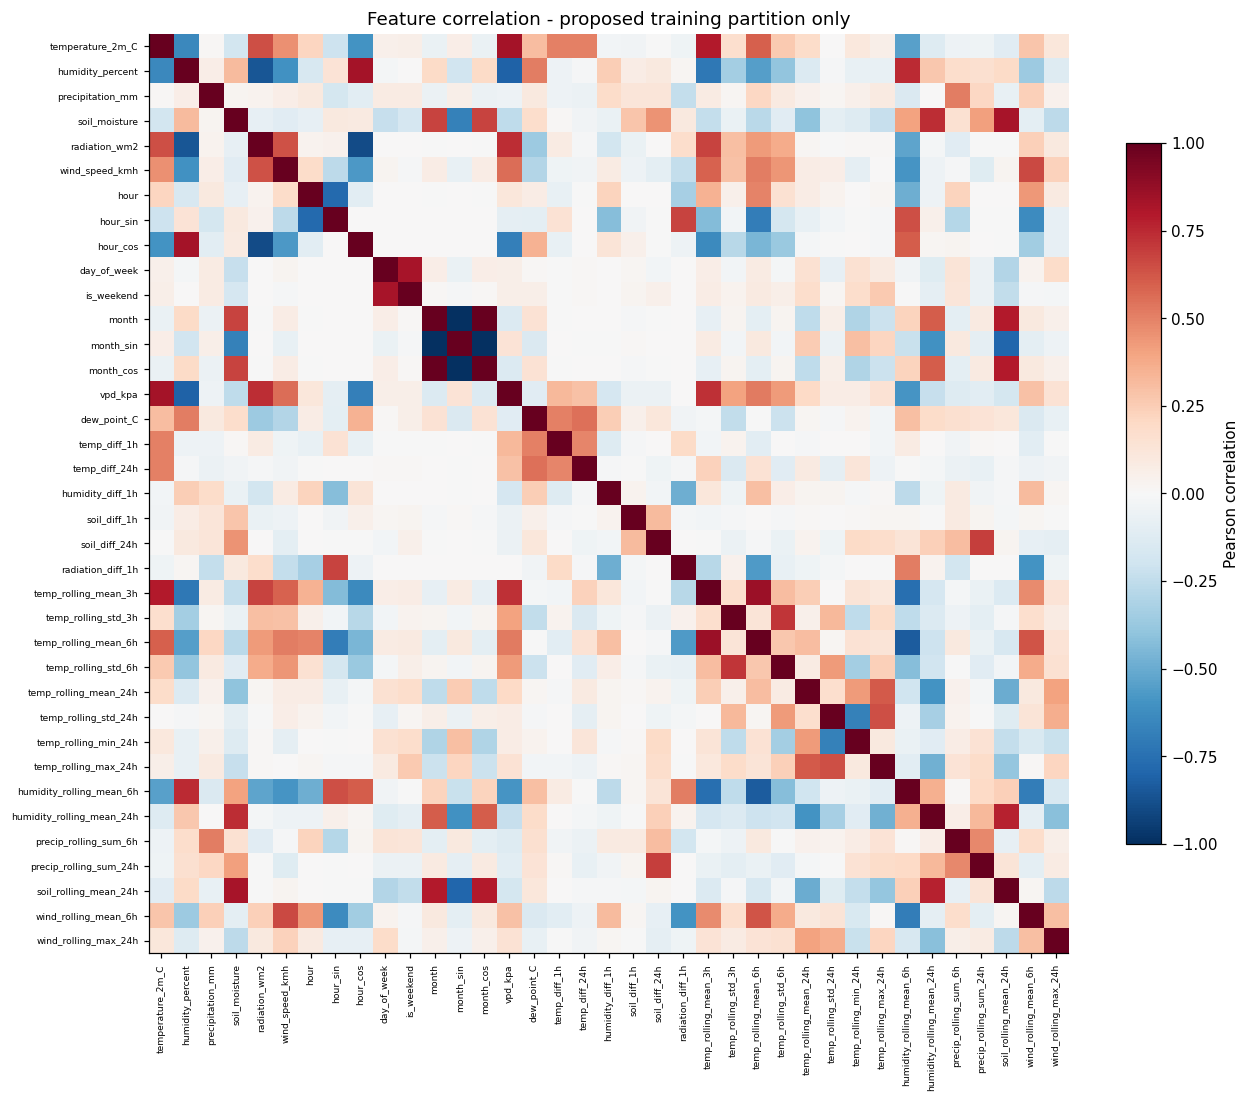

C:\Users\HP\AppData\Local\Temp\ipykernel_28888\852409714.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([train.loc[train.anomaly_class.eq(k),col].to_numpy() for k in [0,1,2]], labels=['0','1','2'],showfliers=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_28888\852409714.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([train.loc[train.anomaly_class.eq(k),col].to_numpy() for k in [0,1,2]], labels=['0','1','2'],showfliers=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_28888\852409714.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([train.loc[train.anomaly_class.eq(k),col].

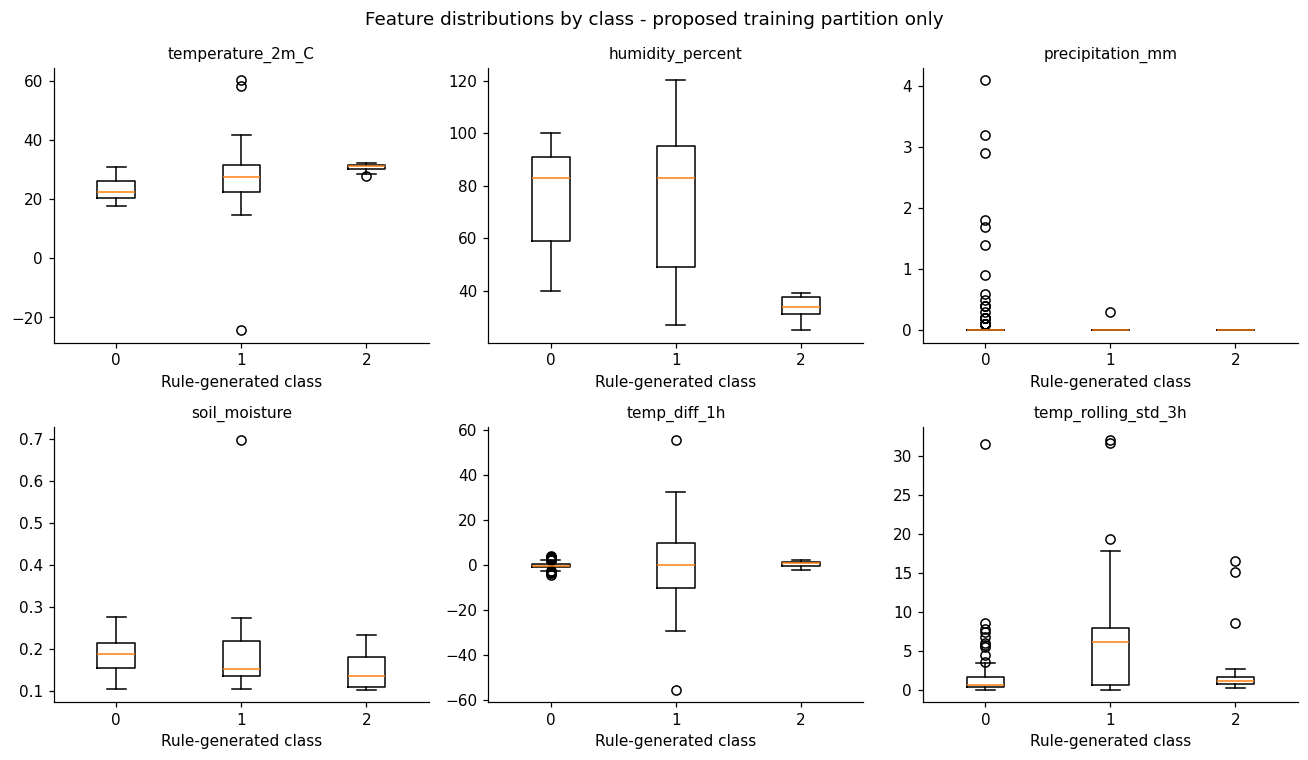

In [6]:
feature_columns = [c for c in df.columns if c not in ['timestamp','anomaly_class','anomaly_reason']]
X_train = df.iloc[:432][feature_columns]
print('Jumlah kandidat fitur:',len(feature_columns))
print('Fitur konstan pada train:', X_train.columns[X_train.nunique()<=1].tolist())
print('Fitur:', ', '.join(feature_columns))
train_corr=X_train.corr()
train_corr.to_csv(OUT/'train_feature_correlations.csv')
fig, ax=plt.subplots(figsize=(12,10))
im=ax.imshow(train_corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(feature_columns)),feature_columns,rotation=90,fontsize=6)
ax.set_yticks(range(len(feature_columns)),feature_columns,fontsize=6)
ax.set_title('Feature correlation - proposed training partition only')
fig.colorbar(im,ax=ax,shrink=.75,label='Pearson correlation')
fig.tight_layout(); savefig('04_train_correlations.png')

train=df.iloc[:432]
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,col in zip(axes.flat,['temperature_2m_C','humidity_percent','precipitation_mm','soil_moisture','temp_diff_1h','temp_rolling_std_3h']):
    ax.boxplot([train.loc[train.anomaly_class.eq(k),col].to_numpy() for k in [0,1,2]], labels=['0','1','2'],showfliers=True)
    ax.set_title(col,fontsize=10)
    ax.set_xlabel('Rule-generated class')
fig.suptitle('Feature distributions by class - proposed training partition only')
fig.tight_layout(); savefig('05_train_class_profiles.png')

## 6. Kelayakan split dan baseline mayoritas

Usulan sederhana: 60% train (432 jam), 20% validation (144 jam), 20% test (144 jam), berurutan tanpa shuffle. Seluruh bagian memiliki tiga kelas, tetapi validation hanya memuat enam contoh Class 2. Satu kesalahan pada enam contoh dapat mengubah recall Class 2 sebesar 16,67 poin persentase. Jangan menganggap perbedaan kecil antar run sebagai bukti kuat.

Alternatif yang lebih kuat adalah walk-forward validation di bagian pengembangan dan menyisakan blok test terakhir. Batas fold harus diaudit agar training dan validation memiliki dukungan kelas yang memadai. Biayanya lebih banyak fitting.

Fitur `.diff()` dan `.rolling()` memakai waktu saat ini dan masa lalu, tanpa imputasi/scaling yang belajar dari seluruh data. Pemeriksaan prefix di bawah membuktikan fitur dan label masa lalu tidak berubah ketika suffix data ditambahkan pada dua batas split. Memakai konteks masa lalu dari train untuk fitur validation/test cocok untuk klasifikasi jam saat ini; ini tidak mengklaim antar-partisi independen, dan bukan forecasting label jam berikutnya. Tidak diperlukan gap hanya karena rolling window 24 jam; gap berguna bila tujuan evaluasi atau horizon target menuntut pemisahan kejadian.

In [7]:
split_rows=[]
partitions={'train':(0,432),'validation':(432,576),'test':(576,720)}
for name,(a,b) in partitions.items():
    part=df.iloc[a:b]
    split_rows.append({'split':name,'rows':len(part),'start':str(part.timestamp.min()),'end':str(part.timestamp.max()), **{f'class_{k}':int(part.anomaly_class.eq(k).sum()) for k in [0,1,2]}})
split_table=pd.DataFrame(split_rows).set_index('split')
display(split_table)
split_table.to_csv(OUT/'proposed_split.csv')

reason_split = pd.crosstab(reasons, pd.Series(np.repeat(['train','validation','test'],[432,144,144]),name='split')).reindex(columns=['train','validation','test'],fill_value=0)
display(reason_split)
reason_split.to_csv(OUT/'reason_coverage_by_split.csv')
for boundary in [432,576]:
    prefix=WeatherPreprocessor().process(raw['faults'].iloc[:boundary])
    pd.testing.assert_frame_equal(prefix,df.iloc[:boundary])
print('Causal prefix checks passed at rows 432 and 576.')

baseline=[]
for name,(a,b) in {'full':(0,720),'validation':(432,576)}.items():
    y=df.anomaly_class.iloc[a:b]
    pred=np.zeros(len(y),dtype=int)
    baseline.append({'partition':name,'accuracy':accuracy_score(y,pred),'macro_f1_fixed_3_classes':f1_score(y,pred,labels=[0,1,2],average='macro',zero_division=0)})
display(pd.DataFrame(baseline))
print('Tidak ada fitting Random Forest atau pemilihan parameter; baseline selalu memprediksi Class 0.')

,rows,start,end,class_0,class_1,class_2
split,,,,,,
train,432,2026-09-20 00:00:00,2026-10-07 23:00:00,360,37,35
validation,144,2026-10-08 00:00:00,2026-10-13 23:00:00,127,11,6
test,144,2026-10-14 00:00:00,2026-10-19 23:00:00,103,13,28


split,train,validation,test
anomaly_reason,,,
Extreme Weather: Heatwave / Heat Stress,0,0,1
Extreme Weather: Severe Dry Air,35,6,27
Hardware Fault: Humidity OOB,4,0,2
Hardware Fault: Negative precipitation,0,1,0
Hardware Fault: Negative radiation,1,0,0
Hardware Fault: Negative wind speed,0,1,1
Hardware Fault: Night radiation glitch,1,0,0
Hardware Fault: Soil moisture OOB,1,1,3
Hardware Fault: Temperature OOB,3,2,2


Causal prefix checks passed at rows 432 and 576.


,partition,accuracy,macro_f1_fixed_3_classes
0,full,0.819444,0.300254
1,validation,0.881944,0.312423


Tidak ada fitting Random Forest atau pemilihan parameter; baseline selalu memprediksi Class 0.


## 7. Implikasi untuk Random Forest dan MLflow

- **Pilihan yang didukung:** supervised multiclass Random Forest sebagai kandidat awal. Input tabular numerik, aturan berambang dan interaksi antarsensor cocok dengan keluarga pohon. Tidak perlu berasumsi distribusi normal atau melakukan scaling untuk split pohon.
- **Batas klaim:** belum ada perbandingan performa antaralgoritma, sehingga tidak ada bukti bahwa RF paling unggul. Logistic Regression dapat menjadi pembanding sederhana; Isolation Forest mendeteksi outlier dan tidak langsung memenuhi target tiga kelas berlabel ini. Fokus LK06 tetap tuning RF sesuai keputusan pengguna.
- **Ketimpangan kelas:** bandingkan `class_weight=None` dan `balanced`; jangan otomatis menganggap balanced menang. Jangan membuang outlier atau clipping batas sensor secara global: itu dapat menghapus sinyal Class 1. Tidak memakai SMOTE sebagai default karena interpolasi dapat merusak hubungan fisik/temporal.
- **Tiga eksperimen terkontrol (usulan):** R1 `n_estimators=100, max_depth=None, min_samples_leaf=1, class_weight=None`; R2 sama dengan R1 kecuali `class_weight='balanced'`; R3 sama dengan R2 kecuali `max_depth=10`. Seluruh run menggunakan fitur, split, dan `random_state=42` yang sama. Pohon lebih banyak bukan jaminan skor membaik.
- **Pemilihan:** ranking berdasarkan `val_f1_macro` dengan `labels=[0,1,2]`; laporkan precision/recall/F1/support per kelas, accuracy, balanced accuracy, confusion matrix, dan gap train/validation. Accuracy saja menyesatkan: baseline normal memperoleh 81,94% pada seluruh snapshot, tetapi macro F1 hanya 30,03%.
- **Evaluasi final:** pilih parameter menggunakan validation, refit model final pada train+validation, lalu evaluasi test sekali. Setelah pemilihan, jangan menyesuaikan parameter berdasarkan hasil test. Semua cache, model, dan metrik harus menyebut sumber data, hash, split, dan fit scope.
- **MLflow:** log parameter, metrik validation per run, model melalui `mlflow.sklearn.log_model`, signature/input example, daftar fitur dan artefak evaluasi. Backend SQLite mendukung tracking/registry lokal. Model terbaik didaftarkan dengan metadata batas klaim dan sumber pseudo-label; model serving menerima fitur dengan kontrak yang sama, bukan raw JSON tanpa preprocessing.
- **Cakupan yang belum diuji:** hanya satu blok temperature stuck di train, tidak ada stuck di validation/test; beberapa fault negatif tidak ada di train. Evaluasi tiga kelas tidak membuktikan semua subtipe fault dikuasai. Cakupan hanya 30 hari satu lokasi, satu seed injeksi, dan label ekstrem sangat didominasi udara kering.
- **Terminologi laporan:** gunakan "klasifikasi terhadap pseudo-label aturan pada data Open-Meteo dan fault sintetis". Ambang agronomis dalam proyek merupakan asumsi labeler; notebook ini tidak memvalidasi ambang tersebut secara ilmiah.

Referensi metode: [RandomForestClassifier](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [validasi time-series](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split), [macro F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html), [backend MLflow](https://mlflow.org/docs/latest/ml/tracking/backend-stores/). Versi environment lokal dicatat di provenance; jangan mengasumsikan API versi terbaru identik dengan versi terpasang.

In [8]:
summary={
    **provenance,
    'quality':quality.reset_index().to_dict(orient='records'),
    'class_counts':{k:{str(c):int(v) for c,v in counts[k].items()} for k in counts},
    'changed_sensor_rows':int(changed.sum()),
    'unmodified_rows_labeled_fault':int((~changed & df.anomaly_class.eq(1)).sum()),
    'proposed_split':split_table.reset_index().to_dict(orient='records'),
    'processed_cache_audit':cache_audit.to_dict(orient='records'),
    'candidate_feature_columns':feature_columns,
    'causal_prefix_checks_passed':[432,576],
    'rf_models_fitted':0,
    'label_source':'deterministic_rule_pseudo_labels',
    'descriptive_holdout_inspection':True,
}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
assert {k:hashlib.md5(p.read_bytes()).hexdigest() for k,p in PATHS.items()} == EXPECTED
print('Artefak EDA tersimpan:',OUT)
print('Hash kedua sumber DVC tetap sesuai snapshot v3.')

Artefak EDA tersimpan: C:\Users\HP\Documents\UB\02 Kuliah\Mata Kuliah\Semester 5\05 MLOps\MLOps-AnomaliCuacaOpenMeteo\Documentation\LK06\eda
Hash kedua sumber DVC tetap sesuai snapshot v3.
